# Introduction

This notebook prepares the cleaned housing dataset for modeling. It separates `median_house_value` as the target, splits the data into training and test sets, and examines multicollinearity among numeric predictors using a correlation matrix and variance inflation factor (VIF). It then creates household-level ratios and an income-by-rooms interaction and reassesses the correlations and VIFs. These checks help identify redundancy and guide later model development; they do not, on their own, show which features will predict house values best.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [2]:
house_cleaned = pd.read_csv("../data/processed/house_cleaned.csv")
house_cleaned.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
house_cleaned.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

### Separate features from target variable and split the dataset

In [6]:
x = house_cleaned.drop(columns=["median_house_value"])
y = house_cleaned["median_house_value"]

In [7]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [8]:
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


### Analyze Multicollinearity

Multicollinearity occurs when two or more predictors contain overlapping linear information. In a regression model, this can make individual coefficient estimates less stable and harder to interpret, even when the model's overall predictions remain useful. A correlation matrix highlights strong pairwise relationships, while VIF estimates how much a predictor's variance is inflated by its relationship with all the other predictors. VIF cutoffs such as 5 or 10 are rules of thumb, not strict pass/fail rules.

In [12]:
# 1. Select numerical features

numeric_features = x_train.select_dtypes(include=["int64", "float64"]).columns

x_train_numeric = x_train[numeric_features].copy()

print("Numerical features:")
print(list(x_train_numeric.columns))

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']


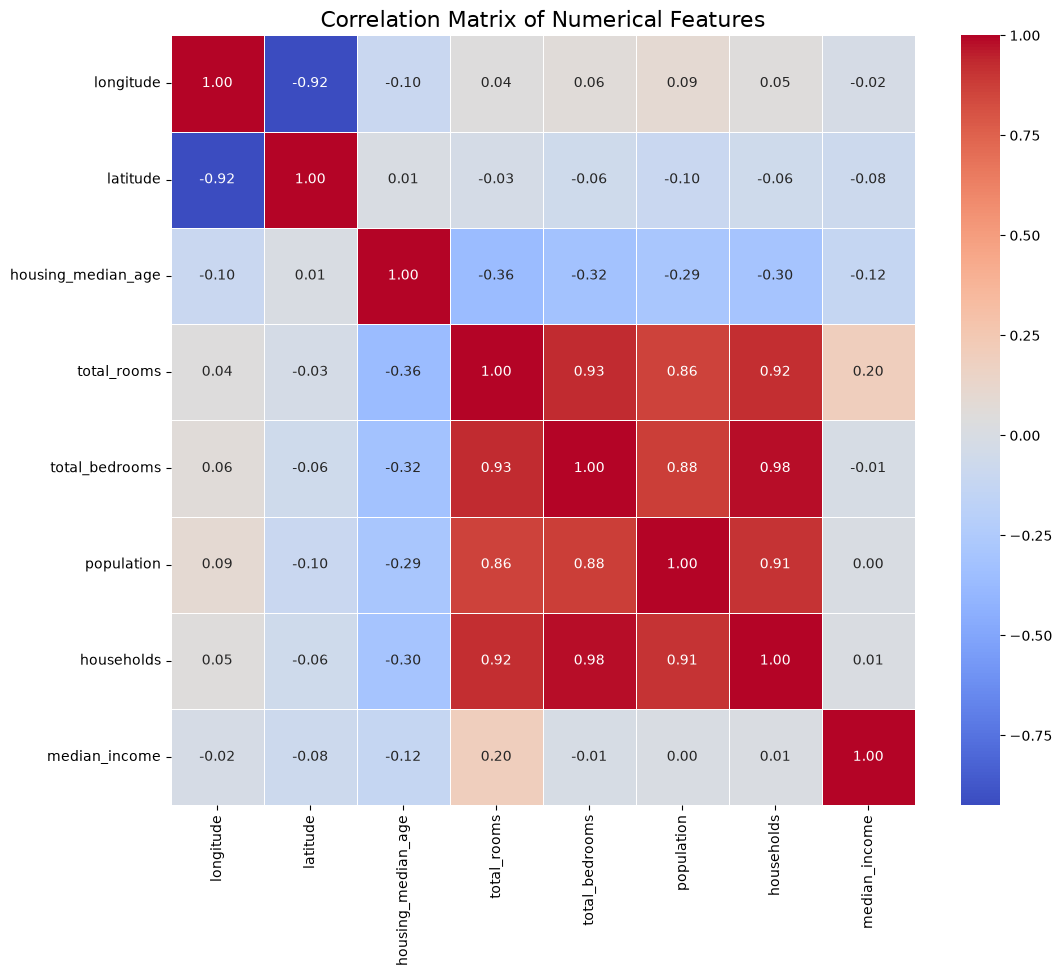

In [13]:
# 2. Calculate correlation matrix

correlation_matrix = x_train_numeric.corr()

plt.figure(figsize=(12,10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)

plt.title("Correlation Matrix of Numerical Features", fontsize=16)
plt.show()

In [14]:
# 3. Measure multicollinearity using Variance Inflation Factor (VIF)

vif_data = pd.DataFrame()

vif_data['Feature'] = x_train_numeric.columns

vif_data['VIF'] = [
    variance_inflation_factor(
        x_train_numeric.values,
        i
    )
    for i in range(x_train_numeric.shape[1])
]

vif_data = vif_data.sort_values(
    by='VIF',
    ascending=False
)

display(vif_data)

,Feature,VIF
4,total_bedrooms,36.307087
6,households,35.824564
3,total_rooms,12.821807
1,latitude,8.798267
0,longitude,8.681823
5,population,6.345431
7,median_income,1.740998
2,housing_median_age,1.257629


The initial correlation matrix shows that several area-size measures move together: total bedrooms and households have the strongest relationship (|r| about 0.98), followed by total rooms with total bedrooms (about 0.93), longitude with latitude (about 0.92), and total rooms with households (about 0.92). Population and households are also strongly correlated (about 0.91). These relationships suggest overlapping information among the neighborhood counts and a geographic relationship between the location coordinates.

The VIF results reinforce this pattern. Total bedrooms (36.31) and households (35.82) are far above common warning thresholds, and total rooms (12.82) is also high. Latitude (8.80), longitude (8.68), and population (6.35) indicate additional, more moderate overlap. By comparison, median income (1.74) and housing median age (1.26) show little inflation from the other predictors in this initial set. The high count-feature VIFs mean their individual coefficients may be difficult to interpret reliably in a linear model.

### Feature Engineering

The engineered variables express housing characteristics in relative rather than raw-count terms, which can make areas of different sizes easier to compare:

- `rooms_per_household` divides total rooms by households to describe the typical room count per household.
- `bedrooms_per_room` measures the share of rooms that are bedrooms, describing housing composition rather than neighborhood size.
- `population_per_household` estimates the number of people per household, a measure of household occupancy.
- `income_x_rooms_per_household` multiplies median income by rooms per household to let a model test whether the relationship associated with one measure changes with the other.

The same formulas are applied to the training and test predictors; the target is not used to construct these features.

In [15]:
# 1. ROOMS_PER_HOUSEHOLD

x_train["rooms_per_household"] = x_train["total_rooms"] / x_train["households"]
x_test["rooms_per_household"] = x_test["total_rooms"] / x_test["households"]

In [16]:
# 2. BEDROOMS_PER_ROOM

x_train["bedrooms_per_room"] = x_train["total_bedrooms"] / x_train["total_rooms"]
x_test["bedrooms_per_room"] = x_test["total_bedrooms"] / x_test["total_rooms"]

In [18]:
# 3. POPULATION PER HOUSEHOLD

x_train["population_per_household"] = x_train["population"] / x_train["households"]
x_test["population_per_household"] = x_test["population"] / x_test["households"]

In [19]:
# Create interaction feature (multiply median income by rooms_per_household)

x_train["income_x_rooms_per_household"] = (x_train["median_income"] * x_train["rooms_per_household"])
x_test["income_x_rooms_per_household"] = (x_test["median_income"] * x_test["rooms_per_household"])

### Check new features and reassess collinearity

In [20]:
x_train[
    [
        "rooms_per_household", 
        "bedrooms_per_room", 
        "population_per_household", 
        "income_x_rooms_per_household"
    ]
].head()

,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms_per_household
14196,5.017657,0.200576,3.691814,16.355553
8267,4.473545,0.232703,1.738095,17.055390
17445,5.645833,0.174486,2.723214,23.465777
14265,4.002817,0.258269,3.994366,7.775472
2271,6.268421,0.180940,2.300000,22.279222


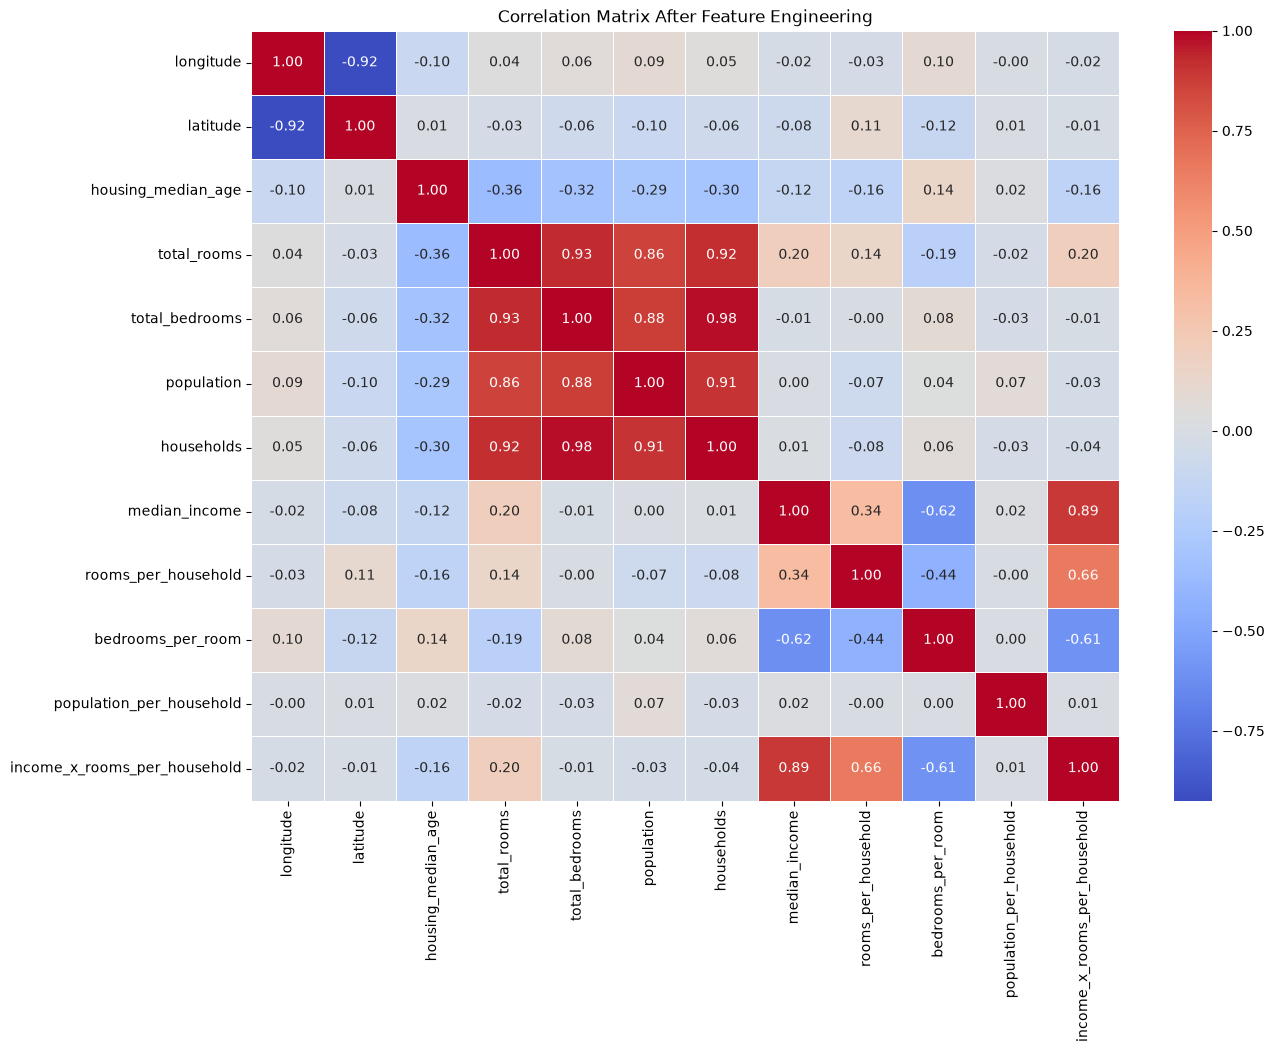

In [ ]:
#Correlation matrix after feature engineering

updated_numeric_features = x_train.select_dtypes(include=['int64', 'float64']).columns

updated_correlation_matrix = x_train[updated_numeric_features].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    updated_correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix After Feature Engineering')
plt.show()

In [22]:
# Updated VIF after feature engineering

updated_vif_data = pd.DataFrame()

updated_vif_data['Feature'] = updated_numeric_features

updated_vif_data['VIF'] = [
    variance_inflation_factor(
        x_train[updated_numeric_features].values,
        i
    )
    for i in range(len(updated_numeric_features))
]

updated_vif_data = updated_vif_data.sort_values(
    by='VIF',
    ascending=False
)

display(updated_vif_data)

,Feature,VIF
4,total_bedrooms,49.937708
6,households,47.027511
3,total_rooms,18.818198
11,income_x_rooms_per_household,17.799747
7,median_income,13.693676
1,latitude,9.519946
0,longitude,9.172626
5,population,6.871230
8,rooms_per_household,4.504011
9,bedrooms_per_room,2.894908


The updated correlation matrix retains the strong relationships among the original count features because feature engineering adds columns without changing those original predictors. Among the engineered features, the income-by-rooms interaction is strongly correlated with median income (r about 0.89) and moderately correlated with rooms per household (about 0.66). Bedrooms per room is moderately correlated with median income (about 0.62), while population per household has little pairwise correlation with the original counts (the largest absolute correlation with one of those counts is about 0.07).

The updated VIF table shows that collinearity remains substantial: total bedrooms is 49.94, households 47.03, and total rooms 18.82. The interaction has a VIF of 17.80, and median income's VIF increases from 1.74 to 13.69 after the interaction is added. In contrast, rooms per household (4.50), bedrooms per room (2.89), and population per household (1.07) have lower VIFs. Thus, the ratios provide less redundant alternatives or additional signals, but the new interaction increases overlap with its component variables; assess their contribution in model validation rather than assuming every engineered feature is beneficial.

### Overall Conclusion

The initial diagnostics show substantial redundancy among neighborhood-size counts: total bedrooms and households have a correlation of about 0.98, total rooms and total bedrooms about 0.93, and total rooms and households about 0.92. Their initial VIFs are also high (36.31 for total bedrooms, 35.82 for households, and 12.82 for total rooms). Several engineered ratios have VIFs below common warning thresholds, but because the original counts were retained, adding ratios does not remove the collinearity among those counts. The income-by-rooms interaction is itself strongly associated with median income (about 0.89) and has a VIF of 17.80; median income's VIF also rises from 1.74 to 13.69 after adding it.

These results are a warning about redundancy and coefficient interpretation, not proof that any feature is useless or that predictive accuracy has improved. Moving forward, compare sensible feature sets and, for coefficient-based models, consider whether to remove or combine redundant counts or use regularization. Evaluate the choices on held-out data with appropriate prediction metrics; the correlation matrix and VIF alone do not measure performance or establish a relationship with the target.